# Fases 1 y 2: normalización y tokenización

**Responsable:** Carmen · **Módulos:** `src/nlp/normalizacion.py`, `src/nlp/tokenizacion.py`

Las dos primeras fases del preprocesamiento preparan el texto que escribe el usuario del chat para el resto del pipeline:

- **Fase 1 – Normalización** (`normalizar(texto) -> str`): pasa a minúsculas, quita tildes, puntuación, URLs, correos, menciones y emojis, y conserva lo que sirve para la intención (números de talla y precio, la ñ, tallas como `s/m`).
- **Fase 2 – Tokenización** (`tokenizar(texto) -> list[str]`): divide el texto normalizado en tokens, resolviendo los casos difíciles del dominio de ropa (`talla-m`, `s/m`, `100bs`, `12.50`).

Las dos funciones son el inicio de `TextPreprocessor` (`src/nlp/pipeline.py`), el primer paso del modelo guardado en `artifacts/modelo.joblib`.

Este notebook:

1. Muestra cada paso de la normalización con ejemplos antes/después y justifica qué se elimina y qué se conserva.
2. Muestra los casos difíciles de la tokenización y por qué un simple `split()` no alcanza.
3. **Justifica con métricas** una decisión de la normalización: conservar los números frente a eliminarlos.

> La comparación con métricas usa **solo el conjunto de entrenamiento** (validación cruzada estratificada de 5 particiones). El conjunto de prueba no se usa para decidir nada.

In [1]:
import os, sys, json, re
from collections import Counter
from pathlib import Path

# El notebook vive en backend/notebooks/: se trabaja desde backend/ para usar las mismas rutas que train.py
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import f1_score

from src.config import config
from src.data.dataset import cargar_intenciones, dividir
from src.nlp.normalizacion import normalizar
from src.nlp.tokenizacion import tokenizar
from src.nlp.pipeline import TextPreprocessor, crear_preprocesador
from src.nlp.vectorizacion import crear_vectorizador

pd.set_option("display.max_colwidth", 90)
SEED = config["project"]["seed"]

df = cargar_intenciones(config["data"]["raw_path"])
X_train, X_test, y_train, y_test = dividir(df, test_size=config["data"]["test_size"], seed=SEED)
print(f"Dataset: {len(df)} frases, {df['intencion'].nunique()} intenciones")
print(f"Entrenamiento: {len(X_train)} · Prueba: {len(X_test)} (no se usa en este notebook)")

Dataset: 1120 frases, 14 intenciones
Entrenamiento: 896 · Prueba: 224 (no se usa en este notebook)


## 1. Normalización (fase 1)

### 1.1 Ejemplos antes/después

Cada fila prueba un caso concreto. La columna **normalizado** es la salida real de `normalizar()`.

In [2]:
ejemplos_norm = [
    ("Mayúsculas",              "Hola, BUENAS TARDES"),
    ("Tildes",                  "¿Cuánto cuesta la camisa?"),
    ("Diéresis",                "Busco una chaqueta de pingüino"),
    ("La ñ se conserva",        "Quiero ropa para niño de un año"),
    ("Signos ¿? ¡!",            "¡¡Hola!! ¿Tienen descuentos??"),
    ("URL",                     "vi este vestido en https://tienda.com/vestido-rojo"),
    ("URL sin http",            "lo vi en www.tienda.com"),
    ("Correo",                  "mi correo es carmen.ventas@gmail.com"),
    ("Mención",                 "@tiendaropa tienen poleras?"),
    ("Emojis",                  "me encanta 😍🔥 ese abrigo 👗"),
    ("Apóstrofo",               "¿Tienen JEAN'S azules?"),
    ("Número de talla",         "pantalón talla 32"),
    ("Precio con moneda",       "algo de menos de 100bs"),
    ("Decimal",                 "cuesta 12.50 o 12,50?"),
    ("Talla con barra",         "hay blusas en S/M?"),
    ("Talla con guion",         "la quiero en Talla-M"),
    ("Todo junto",              "¿Tienen JEAN'S en Talla-M? 😍 https://tienda.com"),
]
tabla_norm = pd.DataFrame(
    [(caso, texto, normalizar(texto)) for caso, texto in ejemplos_norm],
    columns=["caso", "original", "normalizado"],
)
tabla_norm

,caso,original,normalizado
0,Mayúsculas,"Hola, BUENAS TARDES",hola buenas tardes
1,Tildes,¿Cuánto cuesta la camisa?,cuanto cuesta la camisa
2,Diéresis,Busco una chaqueta de pingüino,busco una chaqueta de pinguino
3,La ñ se conserva,Quiero ropa para niño de un año,quiero ropa para niño de un año
4,Signos ¿? ¡!,¡¡Hola!! ¿Tienen descuentos??,hola tienen descuentos
5,URL,vi este vestido en https://tienda.com/vestido-rojo,vi este vestido en
6,URL sin http,lo vi en www.tienda.com,lo vi en
7,Correo,mi correo es carmen.ventas@gmail.com,mi correo es
8,Mención,@tiendaropa tienen poleras?,tienen poleras
9,Emojis,me encanta 😍🔥 ese abrigo 👗,me encanta ese abrigo


**Qué se ve en la tabla:**

- Mayúsculas, tildes, diéresis, signos, URLs, correos, menciones y emojis desaparecen.
- `año` y `niño` mantienen la ñ.
- `jean's` queda como `jeans`: el apóstrofo se quita **sin separar** la palabra, así coincide con "jeans" escrito sin apóstrofo.
- Los números (`32`, `100bs`, `12.50`), la barra de `s/m` y el guion de `talla-m` se conservan; de separarlos se encarga la tokenización (fase 2).
- La coma decimal `12,50` se convierte en `12.50`, así las dos formas de escribir un precio quedan iguales.

### 1.2 Qué se elimina, qué se conserva y por qué

Resumen tomado de la documentación de `src/nlp/normalizacion.py`:

| Elemento | Decisión | Por qué |
|---|---|---|
| Mayúsculas | Se eliminan (todo a minúsculas) | "Polera", "POLERA" y "polera" son la misma palabra; sin esto el vocabulario se triplica. |
| Tildes y diéresis (á, é, ü…) | Se eliminan | En el chat muchos escriben sin tildes ("cuanto cuesta"); así "cuánto" y "cuanto" son el mismo término. |
| Letra **ñ** | **Se conserva** | Cambia el significado: "año" no es "ano", "pequeño" no es "pequeno". |
| URLs, correos y menciones (@usuario) | Se eliminan | Son identificadores únicos que no aportan a la intención y solo agregan ruido al vocabulario. |
| Emojis y símbolos | Se eliminan | En consultas de una tienda de ropa casi nunca definen la intención. |
| Puntuación (¿?¡!.,;:"()…) | Se elimina | La intención la dan las palabras; "¿precio?" y "precio" piden lo mismo. |
| Apóstrofo dentro de palabra | Se elimina sin separar | "jean's" → "jeans", igual que si se escribe sin apóstrofo. |
| **Números** | **Se conservan** | Son tallas ("talla 32") o precios ("100bs"); se justifica con métricas en la sección 3. |
| Decimales ("12.50", "12,50") | Se conservan como "12.50" | Un precio no debe partirse en "12" y "50". |
| Barra entre letras o números ("s/m") | Se conserva | Es una talla combinada; la tokenización la trata como un solo token. |
| Guion entre palabras ("talla-m") | Se conserva | La tokenización lo separa en "talla" y "m". |

### 1.3 Efecto en el dataset real

Se aplica `normalizar()` a todas las frases del dataset y se cuenta cuántas cambian y cuántas palabras distintas hay antes y después (separando por espacios en ambos casos, para que la comparación sea justa).

In [3]:
textos = df["texto"]
normalizados = textos.map(normalizar)
cambian = (textos != normalizados)

vocab_antes = Counter(p for t in textos for p in t.split())
vocab_despues = Counter(p for t in normalizados for p in t.split())

print(f"Frases que cambian al normalizar: {cambian.sum()} de {len(df)} ({cambian.mean():.1%})")
print(f"Palabras distintas antes:   {len(vocab_antes)}")
print(f"Palabras distintas después: {len(vocab_despues)}  (reducción de {1 - len(vocab_despues) / len(vocab_antes):.1%})")

Frases que cambian al normalizar: 162 de 1120 (14.5%)
Palabras distintas antes:   1778
Palabras distintas después: 1661  (reducción de 6.6%)


Qué tipo de cambio aparece en el dataset (una frase puede tener varios):

In [4]:
detectores = {
    "mayúsculas": lambda t: any(c.isupper() for c in t),
    "tildes o diéresis": lambda t: bool(re.search(r"[áéíóúü]", t, re.I)),
    "signos de puntuación": lambda t: bool(re.search(r"[¿?¡!.,;:\"()]", t)),
    "números": lambda t: bool(re.search(r"\d", t)),
    "URL, correo o mención": lambda t: bool(re.search(r"https?://|www\.|@", t)),
    "emojis u otros símbolos": lambda t: bool(re.search(r"[^\w\s¿?¡!.,;:\"()'/\-@áéíóúüñ]", t, re.I)),
}
conteo = pd.DataFrame(
    [(nombre, int(textos.map(f).sum())) for nombre, f in detectores.items()],
    columns=["la frase original tiene", "frases"],
)
conteo["% del dataset"] = (conteo["frases"] / len(df) * 100).round(1)
conteo

,la frase original tiene,frases,% del dataset
0,mayúsculas,1,0.1
1,tildes o diéresis,6,0.5
2,signos de puntuación,155,13.8
3,números,33,2.9
4,"URL, correo o mención",0,0.0
5,emojis u otros símbolos,0,0.0


In [5]:
# Algunas frases reales que cambian (muestra fija por la semilla)
pd.DataFrame({"original": textos[cambian], "normalizado": normalizados[cambian]}).sample(10, random_state=SEED)

,original,normalizado
1115,que ropa deportiva me recomiendas?,que ropa deportiva me recomiendas
1054,que es lo mas popular entre los clientes?,que es lo mas popular entre los clientes
1082,que me recomiendas en color negro?,que me recomiendas en color negro
81,cual es la direccion de la tienda fisica?,cual es la direccion de la tienda fisica
707,tienen datáfono o pos inalambrico para cobro a domicilio,tienen datafono o pos inalambrico para cobro a domicilio
53,hasta que talla manejan en camisas?,hasta que talla manejan en camisas
1044,tienes alguna recomendacion para mi?,tienes alguna recomendacion para mi
77,tienen garantia para cambio por falla?,tienen garantia para cambio por falla
1043,que me sugieres para regalar?,que me sugieres para regalar
1098,que prendas son tendencia esta temporada?,que prendas son tendencia esta temporada


In [6]:
# Palabras que más se unifican: formas distintas del texto original que terminan siendo la misma palabra
formas = {}
for palabra in vocab_antes:
    for p in normalizar(palabra).split():
        formas.setdefault(p, set()).add(palabra)
unificadas = sorted(((p, len(f), ", ".join(sorted(f))) for p, f in formas.items() if len(f) > 1),
                    key=lambda x: -x[1])
pd.DataFrame(unificadas[:12], columns=["palabra normalizada", "formas originales", "ejemplos"])

,palabra normalizada,formas originales,ejemplos
0,comprar,3,"comprar, comprar,, comprar?"
1,regalo,3,"regalo, regalo,, regalo?"
2,recomiendas,3,"recomiendas, recomiendas,, recomiendas?"
3,dias,2,"dias, dias?"
4,dia,2,"dia, dia?"
5,adios,2,"adios, adiós"
6,tienen,2,"tienen, tienen?"
7,jeans,2,"jeans, jeans?"
8,negros,2,"negros, negros?"
9,32,2,"32, 32?"


**Lectura:**

- El dataset está escrito casi todo en minúsculas y sin tildes, así que aquí el efecto principal son los **signos pegados** a las palabras ("comprar", "comprar,", "comprar?"): sin normalizar, el modelo vería tres términos distintos y cada uno tendría menos ejemplos para aprender.
- Que el dataset casi no tenga mayúsculas, tildes, URLs ni emojis **no** hace inútiles esos pasos: los usuarios reales del chat sí escriben "¿Cuánto cuesta?" o pegan un enlace. Como `TextPreprocessor` va dentro del modelo guardado, la misma normalización se aplica a cada consulta en producción y la lleva a la forma en que se entrenó el modelo.

Además la normalización es **idempotente** (aplicarla dos veces da lo mismo), algo que se usa en la sección 3:

In [7]:
assert all(normalizar(t) == t for t in normalizados), "normalizar no es idempotente"
print("normalizar(normalizar(t)) == normalizar(t) para las", len(normalizados), "frases")

normalizar(normalizar(t)) == normalizar(t) para las 1120 frases


## 2. Tokenización (fase 2)

### 2.1 Casos difíciles del dominio

Se compara `tokenizar(normalizar(texto))` con dos alternativas simples:

- `texto.split()` sobre el texto original.
- `split()` sobre el texto ya normalizado (para ver qué resuelve la tokenización por sí sola).

In [8]:
casos_tok = [
    ("Guion talla",         "Lo quiero en Talla-M",       "talla-m -> talla, m"),
    ("Talla en letras",     "Hay polos XL?",              "xl es un solo token"),
    ("Talla combinada",     "blusas en S/M",              "s/m es un solo token"),
    ("Talla numérica",      "tallas 38/40 en jeans",      "38/40 es un solo token"),
    ("Precio + moneda",     "menos de 100bs",             "100bs -> 100, bs"),
    ("Decimal",             "cuesta 12.50?",              "12.50 no se parte"),
    ("Decimal con coma",    "cuesta 12,50",               "12,50 -> 12.50"),
    ("Apóstrofo",           "¿Tienen JEAN'S?",            "jean's -> jeans"),
    ("Talla pegada",        "pantalon talla32",           "talla32 -> talla, 32"),
    ("Signos pegados",      "¿Precio?¡Gracias!",          "sin signos pegados"),
]
filas = []
for caso, texto, esperado in casos_tok:
    filas.append({
        "caso": caso,
        "original": texto,
        "texto.split()": texto.split(),
        "normalizar + split()": normalizar(texto).split(),
        "tokenizar(normalizar)": tokenizar(normalizar(texto)),
        "esperado": esperado,
    })
pd.set_option("display.max_colwidth", 45)
tabla_tok = pd.DataFrame(filas)
tabla_tok

,caso,original,texto.split(),normalizar + split(),tokenizar(normalizar),esperado
0,Guion talla,Lo quiero en Talla-M,"[Lo, quiero, en, Talla-M]","[lo, quiero, en, talla-m]","[lo, quiero, en, talla, m]","talla-m -> talla, m"
1,Talla en letras,Hay polos XL?,"[Hay, polos, XL?]","[hay, polos, xl]","[hay, polos, xl]",xl es un solo token
2,Talla combinada,blusas en S/M,"[blusas, en, S/M]","[blusas, en, s/m]","[blusas, en, s/m]",s/m es un solo token
3,Talla numérica,tallas 38/40 en jeans,"[tallas, 38/40, en, jeans]","[tallas, 38/40, en, jeans]","[tallas, 38/40, en, jeans]",38/40 es un solo token
4,Precio + moneda,menos de 100bs,"[menos, de, 100bs]","[menos, de, 100bs]","[menos, de, 100, bs]","100bs -> 100, bs"
5,Decimal,cuesta 12.50?,"[cuesta, 12.50?]","[cuesta, 12.50]","[cuesta, 12.50]",12.50 no se parte
6,Decimal con coma,"cuesta 12,50","[cuesta, 12,50]","[cuesta, 12.50]","[cuesta, 12.50]","12,50 -> 12.50"
7,Apóstrofo,¿Tienen JEAN'S?,"[¿Tienen, JEAN'S?]","[tienen, jeans]","[tienen, jeans]",jean's -> jeans
8,Talla pegada,pantalon talla32,"[pantalon, talla32]","[pantalon, talla32]","[pantalon, talla, 32]","talla32 -> talla, 32"
9,Signos pegados,¿Precio?¡Gracias!,[¿Precio?¡Gracias!],"[precio, gracias]","[precio, gracias]",sin signos pegados


**Por qué `split()` no alcanza:**

- Sobre el texto original, `split()` deja los signos pegados (`"XL?"`, `"¿Tienen"`) y las mayúsculas, así que la misma palabra aparece con varias formas.
- Aun normalizando primero, `split()` deja `talla-m` y `100bs` como un único token: el modelo no reconocería la palabra `talla` ni la moneda `bs`, y cada combinación (`talla-m`, `talla-l`, `talla-xl`…) sería un término nuevo y raro.
- `tokenizar()` usa una expresión regular con un orden de prioridad: primero tallas con barra (`s/m`, `38/40`), luego números (enteros o decimales) y por último palabras. Por eso separa número y letras (`100bs` → `100`, `bs`) pero mantiene unidas las tallas combinadas y los decimales.

In [9]:
# Comprobación de los casos documentados en el módulo
assert tokenizar(normalizar("talla-m")) == ["talla", "m"]
assert tokenizar(normalizar("xl")) == ["xl"]
assert tokenizar(normalizar("s/m")) == ["s/m"]
assert tokenizar(normalizar("100bs")) == ["100", "bs"]
assert tokenizar(normalizar("12.50")) == ["12.50"]
assert tokenizar(normalizar("jean's")) == ["jeans"]
print("Todos los casos difíciles se tokenizan como se espera")

Todos los casos difíciles se tokenizan como se espera


### 2.2 Estadísticas en el dataset

Tokens por frase y cuántos tokens son tallas o números.

**Cómo leer el gráfico:** cada barra corresponde a un largo de frase (eje horizontal: cuántos tokens tiene la frase después de normalizar y tokenizar). La altura de la barra, y el número encima, dice **cuántas frases del dataset tienen ese largo**. Por ejemplo, la barra del 7 indica cuántas frases tienen exactamente 7 tokens.

Tokens por frase:


count    1120.00
mean        8.40
std         2.59
min         2.00
25%         6.00
50%         8.00
75%        10.00
max        16.00


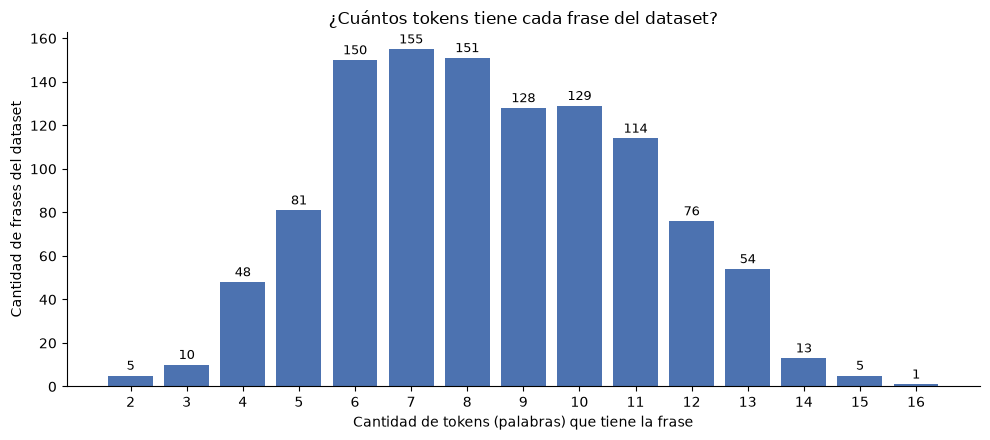

El largo más común es 7 tokens (155 frases). El 88% de las frases tiene entre 5 y 12 tokens: son consultas cortas, típicas de un chat.


In [10]:
pd.set_option("display.max_colwidth", 90)
tokens = df["texto"].map(lambda t: tokenizar(normalizar(t)))
n_tokens = tokens.map(len)
print("Tokens por frase:")
print(n_tokens.describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(10, 4.5))
conteos = n_tokens.value_counts().sort_index()
barras = ax.bar(conteos.index, conteos.values, color="#4C72B0")
ax.bar_label(barras, padding=2, fontsize=9)  # cantidad de frases encima de cada barra
ax.set_xticks(conteos.index)
ax.set_xlabel("Cantidad de tokens (palabras) que tiene la frase")
ax.set_ylabel("Cantidad de frases del dataset")
ax.set_title("¿Cuántos tokens tiene cada frase del dataset?")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

mas_comun = conteos.idxmax()
print(f"El largo más común es {mas_comun} tokens ({conteos.max()} frases). "
      f"El {((n_tokens >= 5) & (n_tokens <= 12)).mean():.0%} de las frases tiene entre 5 y 12 tokens: "
      "son consultas cortas, típicas de un chat.")

In [11]:
TALLAS_LETRA = {"xxs", "xs", "s", "m", "l", "xl", "xxl", "xxxl"}

def tipo_token(tok):
    if "/" in tok:
        return "talla combinada (s/m, 38/40)"
    if re.fullmatch(r"\d+\.\d+", tok):
        return "número decimal"
    if tok.isdigit():
        return "número entero"
    if tok in TALLAS_LETRA:
        return "talla en letras"
    return "palabra"

todos = [t for toks in tokens for t in toks]
tipos = Counter(tipo_token(t) for t in todos)
resumen_tipos = pd.DataFrame(tipos.most_common(), columns=["tipo de token", "apariciones"])
resumen_tipos["frases que lo contienen"] = [
    int(tokens.map(lambda toks, tipo=tipo: any(tipo_token(t) == tipo for t in toks)).sum())
    for tipo in resumen_tipos["tipo de token"]
]
print(f"Total de tokens en el dataset: {len(todos)} · tokens distintos: {len(set(todos))}")
resumen_tipos

Total de tokens en el dataset: 9413 · tokens distintos: 1663


,tipo de token,apariciones,frases que lo contienen
0,palabra,9348,1120
1,número entero,42,33
2,talla en letras,23,19


In [12]:
# Ejemplos de cada tipo especial y en qué intención aparecen las frases con números
especiales = Counter(t for t in todos if tipo_token(t) != "palabra")
print("Tokens de talla o número más frecuentes:", especiales.most_common(15))

con_numero = tokens.map(lambda toks: any(tipo_token(t).startswith("número") or "/" in t for t in toks))
por_intencion = df.loc[con_numero, "intencion"].value_counts()
pd.DataFrame({"frases con números": por_intencion,
              "% de la intención": (por_intencion / df["intencion"].value_counts()[por_intencion.index] * 100).round(1)})

Tokens de talla o número más frecuentes: [('s', 6), ('l', 5), ('m', 4), ('32', 3), ('xl', 3), ('34', 3), ('30', 3), ('10', 3), ('xxl', 2), ('5', 2), ('xs', 2), ('50', 2), ('24', 2), ('7', 1), ('2', 1)]


,frases con números,% de la intención
intencion,,
consultar_tallas,14,17.5
reporte_ventas,4,5.0
productos_mas_vendidos,4,5.0
metodos_pago,3,3.8
stock_bajo,3,3.8
horarios_ubicacion,2,2.5
consultar_stock,1,1.2
consultar_precio,1,1.2
envios,1,1.2


**Lectura:** los números son pocos (menos del 3 % de las frases) y se concentran en `consultar_tallas`. Si conservarlos aporta algo, debería notarse sobre todo en esa intención. La sección siguiente lo mide.

## 3. Comparación con métricas: conservar números vs eliminarlos

La decisión más discutible de la normalización es **conservar los números**: muchas guías de preprocesamiento recomiendan eliminarlos para reducir el vocabulario. Aquí se mide si eso conviene en este dominio.

- **Conservar números** (lo que hace `normalizar()`): el pipeline de producción tal cual.
- **Eliminar números** (alternativa definida solo en este notebook, sin tocar el módulo): se normaliza y después se borra todo dígito. Así `talla 32` → `talla`, `100bs` → `bs`, `12.50` y `38/40` desaparecen.

Todo lo demás queda igual al pipeline de producción:
`preprocesamiento (fases 1-4, config.yaml) → crear_vectorizador(config) → LogisticRegression` con los mejores hiperparámetros guardados en `artifacts/metricas.json`.
La variante solo agrega un paso antes de `TextPreprocessor`; como `normalizar()` es idempotente (sección 1.3), el resto del preprocesamiento recibe un texto equivalente al de producción salvo por los números.

In [13]:
def normalizar_sin_numeros(texto):
    # Versión alternativa SOLO para esta comparación: normaliza y borra los dígitos
    return re.sub(r"\d", " ", normalizar(texto))

def quitar_numeros(X):
    return [normalizar_sin_numeros(t) for t in X]

for frase in ["pantalón talla 32", "algo de menos de 100bs", "cuesta 12.50", "tallas 38/40 en jeans"]:
    print(f"{frase!r:28} conservar: {normalizar(frase)!r:26} eliminar: {' '.join(normalizar(normalizar_sin_numeros(frase)).split())!r}")

'pantalón talla 32'          conservar: 'pantalon talla 32'        eliminar: 'pantalon talla'
'algo de menos de 100bs'     conservar: 'algo de menos de 100bs'   eliminar: 'algo de menos de bs'
'cuesta 12.50'               conservar: 'cuesta 12.50'             eliminar: 'cuesta'
'tallas 38/40 en jeans'      conservar: 'tallas 38/40 en jeans'    eliminar: 'tallas en jeans'


In [14]:
metricas = json.loads(Path(config["artifacts"]["metrics_path"]).read_text(encoding="utf-8"))
mejores = metricas["modelos"]["regresion_logistica"]["mejores_parametros"]
C = float(mejores["modelo__C"])
cw = mejores["modelo__class_weight"]
cw = None if cw in (None, "None") else cw
fijos = config["models"]["logistic_regression"]["fixed_params"]
print(f"Regresión logística: C={C}, class_weight={cw}, parámetros fijos={fijos}")

def armar(eliminar_numeros):
    pasos = []
    if eliminar_numeros:
        pasos.append(("quitar_numeros", FunctionTransformer(quitar_numeros)))
    pasos += [
        ("preprocesamiento", crear_preprocesador(config)),
        ("vectorizador", crear_vectorizador(config)),
        ("modelo", LogisticRegression(C=C, class_weight=cw, **fijos)),
    ]
    return Pipeline(pasos)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
variantes = {"conservar números (producción)": False, "eliminar números": True}

filas, predicciones = [], {}
for nombre, eliminar in variantes.items():
    cv = cross_validate(armar(eliminar), X_train, y_train, cv=skf, scoring=["f1_macro", "accuracy"])
    predicciones[nombre] = cross_val_predict(armar(eliminar), X_train, y_train, cv=skf)
    filas.append({
        "variante": nombre,
        "F1 macro CV (media)": cv["test_f1_macro"].mean(),
        "F1 macro CV (desv.)": cv["test_f1_macro"].std(),
        "exactitud CV": cv["test_accuracy"].mean(),
        "F1 macro por partición": np.round(cv["test_f1_macro"], 3).tolist(),
    })
resultados = pd.DataFrame(filas)
resultados.round(4)

Regresión logística: C=10.0, class_weight=balanced, parámetros fijos={'max_iter': 1000, 'solver': 'lbfgs', 'random_state': 42}


,variante,F1 macro CV (media),F1 macro CV (desv.),exactitud CV,F1 macro por partición
0,conservar números (producción),0.8409,0.0174,0.8415,"[0.815, 0.86, 0.844, 0.828, 0.858]"
1,eliminar números,0.8409,0.0174,0.8415,"[0.815, 0.86, 0.844, 0.828, 0.858]"


In [15]:
f1_cons, f1_elim = resultados["F1 macro CV (media)"]
print(f"Diferencia (conservar - eliminar): {f1_cons - f1_elim:+.4f} de F1 macro")
print(f"Referencia: mejor_cv_score guardado por train.py = {metricas['modelos']['regresion_logistica']['mejor_cv_score']}")

Diferencia (conservar - eliminar): +0.0000 de F1 macro
Referencia: mejor_cv_score guardado por train.py = 0.8409


### 3.1 Dónde cambia el resultado: F1 por intención

Se usan las predicciones de validación cruzada (cada frase se predice con un modelo que no la vio en su entrenamiento) y se calcula el F1 de cada intención con las dos variantes.

In [16]:
etiquetas = sorted(y_train.unique())
nombres = list(variantes)
f1_por_intencion = pd.DataFrame({
    nombre: f1_score(y_train, predicciones[nombre], labels=etiquetas, average=None) for nombre in nombres
}, index=etiquetas)
f1_por_intencion["diferencia"] = f1_por_intencion[nombres[0]] - f1_por_intencion[nombres[1]]
f1_por_intencion = f1_por_intencion.sort_values("diferencia", ascending=False)

pred_cons, pred_elim = predicciones[nombres[0]], predicciones[nombres[1]]
print(f"Frases del entrenamiento con distinta predicción entre las dos variantes: {(pred_cons != pred_elim).sum()} de {len(y_train)}")
print(f"Mayor diferencia de F1 en una intención: {f1_por_intencion['diferencia'].abs().max():.4f}")
f1_por_intencion.round(3)

Frases del entrenamiento con distinta predicción entre las dos variantes: 0 de 896
Mayor diferencia de F1 en una intención: 0.0000


,conservar números (producción),eliminar números,diferencia
consultar_precio,0.871,0.871,0.0
consultar_stock,0.752,0.752,0.0
consultar_tallas,0.884,0.884,0.0
despedida,0.969,0.969,0.0
devoluciones,0.797,0.797,0.0
envios,0.859,0.859,0.0
horarios_ubicacion,0.860,0.860,0.0
metodos_pago,0.859,0.859,0.0
productos_mas_vendidos,0.803,0.803,0.0
recomendar_productos,0.824,0.824,0.0


### 3.2 Por qué no cambia: las frases con números

Las métricas iguales no significan que los números no hagan nada: cambian las **probabilidades** del modelo, pero no lo suficiente para cambiar la intención ganadora. Se miran las frases del entrenamiento que tienen algún número y la probabilidad que cada variante le da a la intención correcta (predicción de validación cruzada).

In [17]:
probas = {nombre: cross_val_predict(armar(eliminar), X_train, y_train, cv=skf, method="predict_proba")
          for nombre, eliminar in variantes.items()}
clases = np.array(etiquetas)  # predict_proba ordena las clases alfabéticamente
idx_real = np.searchsorted(clases, y_train.to_numpy())
filas_idx = np.arange(len(y_train))

tiene_numero = X_train.str.contains(r"\d").to_numpy()
frases_num = pd.DataFrame({
    "frase": X_train.to_numpy(),
    "real": y_train.to_numpy(),
    "pred. conservar": pred_cons,
    "pred. eliminar": pred_elim,
    "P(real) conservar": probas[nombres[0]][filas_idx, idx_real],
    "P(real) eliminar": probas[nombres[1]][filas_idx, idx_real],
})[tiene_numero]
frases_num["diferencia P"] = frases_num["P(real) conservar"] - frases_num["P(real) eliminar"]

print(f"Frases del entrenamiento con números: {tiene_numero.sum()} de {len(X_train)} ({tiene_numero.mean():.1%})")
print(f"Aciertos con conservar: {(frases_num['pred. conservar'] == frases_num['real']).sum()} · "
      f"con eliminar: {(frases_num['pred. eliminar'] == frases_num['real']).sum()}")
print(f"P(intención real) media: conservar {frases_num['P(real) conservar'].mean():.3f} · "
      f"eliminar {frases_num['P(real) eliminar'].mean():.3f}")
print(f"Mayor cambio de probabilidad en una frase (todo el entrenamiento): "
      f"{np.abs(probas[nombres[0]] - probas[nombres[1]]).max():.3f}")
frases_num.sort_values("diferencia P", ascending=False).round(3)

Frases del entrenamiento con números: 24 de 896 (2.7%)
Aciertos con conservar: 19 · con eliminar: 19
P(intención real) media: conservar 0.580 · eliminar 0.594
Mayor cambio de probabilidad en una frase (todo el entrenamiento): 0.124


,frase,real,pred. conservar,pred. eliminar,P(real) conservar,P(real) eliminar,diferencia P
801,la talla m me quedara si mido 170 y peso 65 kilos,consultar_tallas,consultar_tallas,consultar_tallas,0.801,0.796,0.006
776,tienen pantalones cargo en talla 36 para varon,consultar_tallas,consultar_tallas,consultar_tallas,0.775,0.769,0.006
635,que requisitos piden para extender credito a 30 dias,metodos_pago,devoluciones,devoluciones,0.075,0.070,0.005
353,el costo de envio es gratuito por compras mayores a 300 bolivianos,envios,envios,envios,0.788,0.784,0.004
399,tienen tallas intermedias como 31 o 33 en jeans,consultar_tallas,consultar_tallas,consultar_tallas,0.889,0.887,0.002
631,dame el acumulado de ingresos por ventas hasta las 6 de la tarde,reporte_ventas,reporte_ventas,reporte_ventas,0.596,0.595,0.001
312,vienen en talla 28 los jeans para dama,consultar_tallas,consultar_tallas,consultar_tallas,0.917,0.917,0.000
87,cuanto se ha vendido en prendas de vestir durante las ultimas 24 horas,reporte_ventas,ventas_por_categoria,ventas_por_categoria,0.155,0.154,0.000
147,se puede reservar una prenda con un adelanto del 20 por ciento,metodos_pago,devoluciones,devoluciones,0.006,0.007,-0.000
315,el repartidor lleva cambio si pago con billetes grandes de 100 o 200,metodos_pago,devoluciones,devoluciones,0.277,0.279,-0.001


In [18]:
# Cuántas veces aparece cada número en el entrenamiento: si casi todos son únicos, el modelo no puede aprender de ellos
numeros_train = Counter(t for frase in X_train for t in tokenizar(normalizar(frase)) if re.match(r"\d", t))
repeticiones = Counter(numeros_train.values())
print(f"Números distintos en el entrenamiento: {len(numeros_train)}")
for veces, cantidad in sorted(repeticiones.items()):
    print(f"  aparecen {veces} vez/veces: {cantidad} números")

Números distintos en el entrenamiento: 24
  aparecen 1 vez/veces: 20 números
  aparecen 2 vez/veces: 3 números
  aparecen 3 vez/veces: 1 números


## 4. Conclusiones y decisiones

### Normalización (fase 1)

- Se pasa a minúsculas y se eliminan tildes, diéresis, puntuación, URLs, correos, menciones y emojis; se conservan la **ñ**, los **números**, los decimales (`12,50` → `12.50`), la barra de `s/m` y el guion de `talla-m`.
- En el dataset cambian **162 de 1.120 frases (14,5 %)** y las palabras distintas bajan de **1.778 a 1.661 (−6,6 %)**. El efecto principal son los signos pegados a las palabras ("comprar?", "comprar,"), porque el dataset casi no tiene mayúsculas ni tildes.
- Los demás pasos (mayúsculas, tildes, URLs, emojis) se justifican por lo que escriben los usuarios reales del chat: `TextPreprocessor` está dentro del modelo guardado y aplica la misma normalización a cada consulta.
- `normalizar()` es idempotente: aplicarla dos veces no cambia el resultado.

### Tokenización (fase 2)

- `split()` no alcanza: deja signos pegados (`"XL?"`) y no separa `talla-m` ni `100bs`.
- `tokenizar()` resuelve los casos del dominio: `talla-m` → `talla`, `m`; `100bs` → `100`, `bs`; `talla32` → `talla`, `32`; y mantiene unidos `s/m`, `38/40` y `12.50`.
- Las frases tienen en promedio **8,4 tokens** (entre 2 y 16). Hay **42 números enteros** y **23 tallas en letras** en 9.413 tokens; los números se concentran en `consultar_tallas` (17,5 % de sus frases).

### Conservar números vs eliminarlos (comparación con métricas)

| Variante | F1 macro CV (media ± desv.) | Exactitud CV |
|---|---|---|
| Conservar números (producción) | 0,8409 ± 0,0174 | 0,8415 |
| Eliminar números | 0,8409 ± 0,0174 | 0,8415 |

- Con regresión logística (C=10, class_weight=balanced) y validación cruzada estratificada de 5 particiones sobre el entrenamiento, **las dos variantes dan exactamente el mismo resultado**: ninguna de las 896 frases cambia de predicción y el F1 de todas las intenciones, incluida `consultar_tallas` (0,884), es igual.
- **Por qué:** solo 24 frases del entrenamiento (2,7 %) tienen números, y de los 24 números distintos, **20 aparecen una sola vez**. Un token que aparece una vez no ayuda a predecir otras frases; la señal de "talla" la da la palabra `talla`, no el número.
- Los números sí mueven las probabilidades (hasta 0,124 en una frase), pero sin cambiar la intención ganadora. En las frases con números, la probabilidad media de la intención correcta es 0,580 conservándolos y 0,594 eliminándolos: una diferencia pequeña que no cambia ningún acierto (19 de 24 en las dos variantes).

**Decisión: se conservan los números.** Las métricas no muestran diferencia, así que eliminarlos no mejora nada y sí perdería información. Se conservan por criterio del dominio: en una tienda de ropa los números son tallas (`32`, `38/40`) y precios (`100bs`), y esa información la necesitará el asistente para responder (por ejemplo, buscar la talla pedida en el catálogo). Si el dataset crece con más consultas de tallas y precios, conviene repetir esta comparación.

## 5. Capturas del proyecto: normalización y tokenización en la aplicación

Las siguientes imágenes son del frontend del proyecto, panel **"Cómo se procesa el texto"**, recortadas para mostrar solo los tres primeros pasos: el texto tal como lo escribió el usuario, el resultado de `normalizar()` y el de `tokenizar()`. Los valores los calcula el backend con los mismos módulos de este notebook (`POST /chat` → `preprocesar_pasos`).

### 5.1 Mayúsculas, apóstrofo, emoji y URL

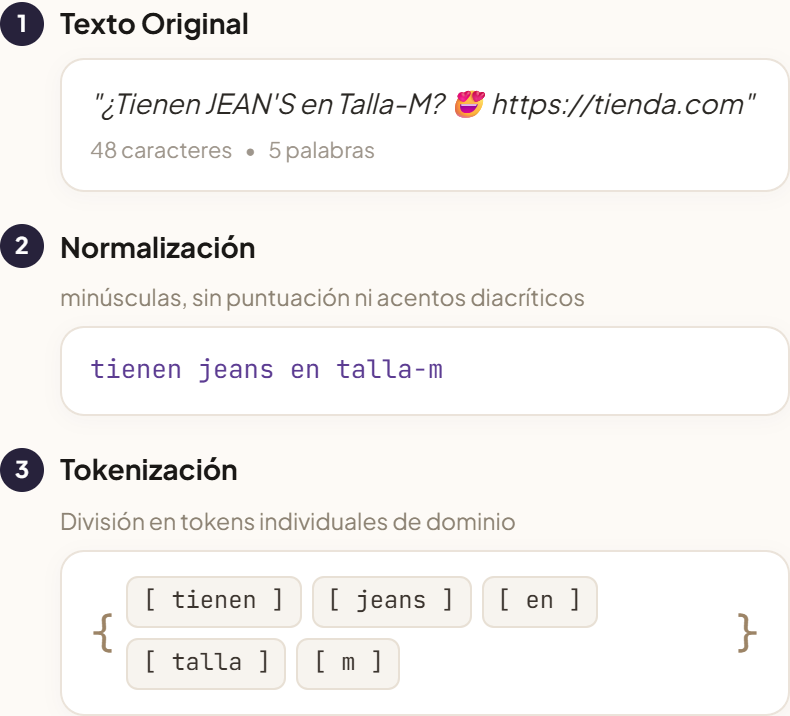

`JEAN'S` pasa a `jeans`, el emoji y la URL desaparecen y `Talla-M` queda como `talla-m`; la tokenización lo separa en `talla` y `m`.

### 5.2 Tildes, signos, talla numérica y precio

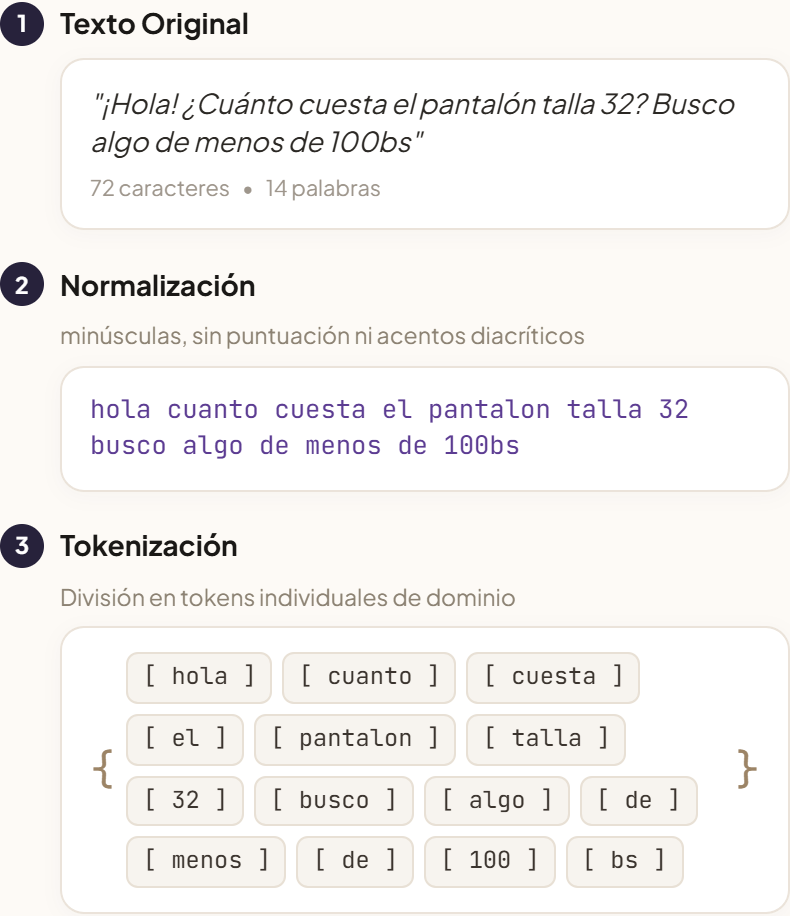

Se quitan `¡ ! ¿ ?` y las tildes (`cuánto` → `cuanto`, `pantalón` → `pantalon`); el número de talla `32` se conserva y `100bs` se separa en `100` y `bs`.

### 5.3 Mención, talla combinada y decimal con coma

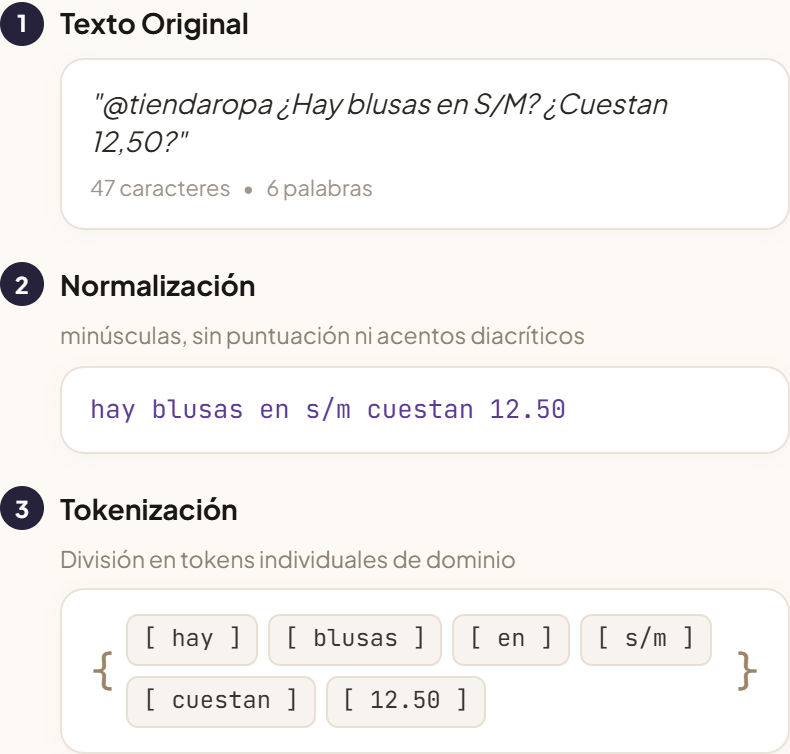

La mención `@tiendaropa` se elimina, `S/M` queda como un solo token `s/m` y `12,50` se convierte en el decimal `12.50` sin partirse.